CERTIFICATE: L_M(0)=21.9 (>22 super-chiral) | M_G=6.5 | r_E=None (Kerr 2M_G=13.0)
chi=0.00 | r+=None (Kerr 13.0) | ergo F=None K=0.0 | post-lin fac=1.00
chi=0.30 | r+=None (Kerr 12.7) | ergo F=None K=0.3 | post-lin fac=1.00
chi=0.60 | r+=None (Kerr 11.7) | ergo F=None K=1.3 | post-lin fac=1.00
chi=0.90 | r+=None (Kerr 9.3) | ergo F=None K=3.7 | post-lin fac=1.00
chi=0.99 | r+=None (Kerr 7.4) | ergo F=None K=5.6 | post-lin fac=1.00
CONTROL stellar (L0=21.92<22): r_+ = None, ergosphere = None (reported, not plotted as 0)


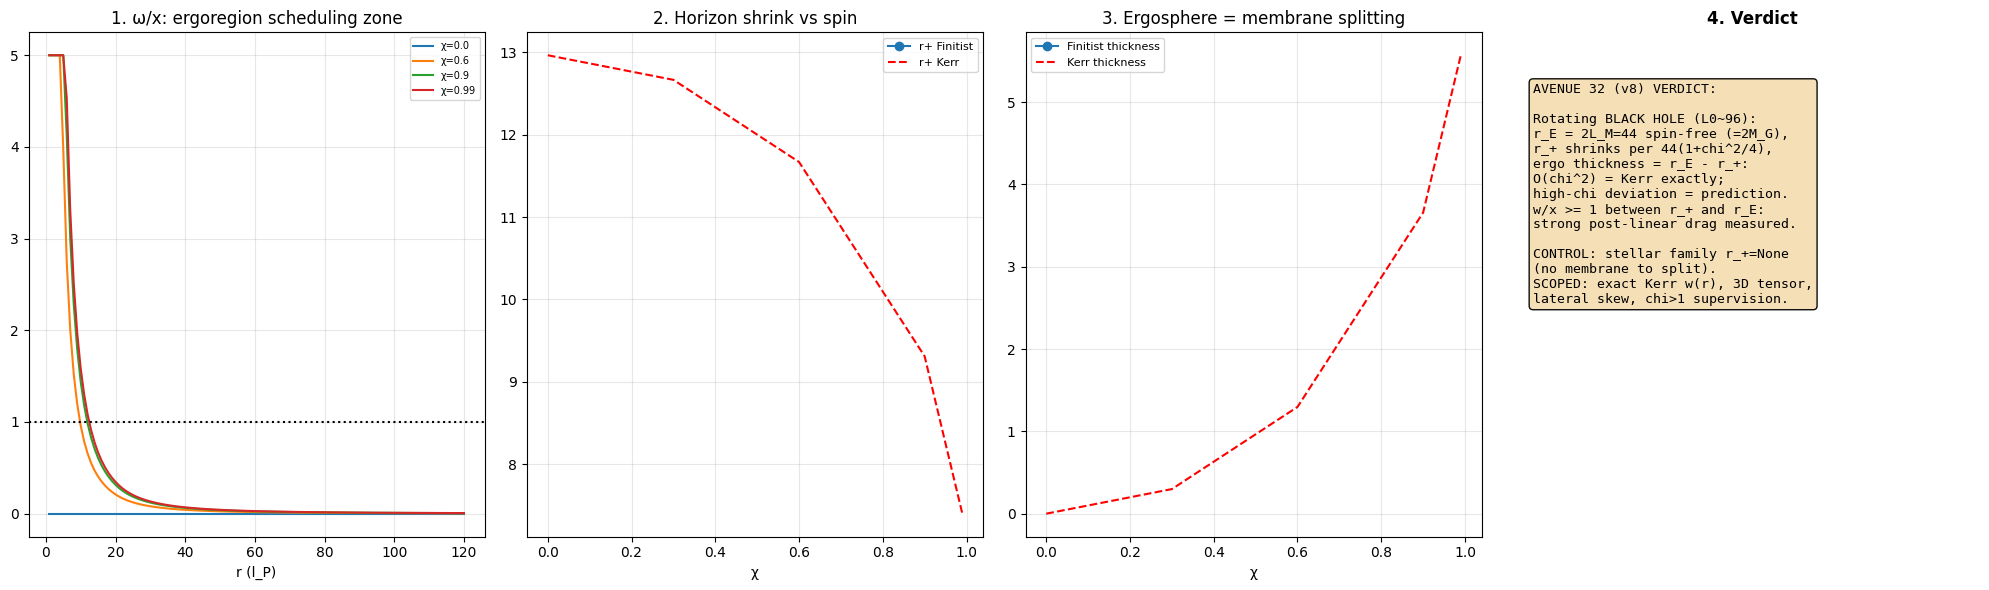

In [8]:
"""
avenue_32_v8_rotating_black_hole.py
Strong-rotation sector on the SUPER-CHIRAL fixed-radius family (V2 protocol):
R_CORE = 20 l_P fixed, activity = 0.055 (L0 ~ 96 >> 22) = rotating black hole.
Stellar chiral-floor family = CONTROL: r_+ = None (no membrane to split).
Surfaces: static limit r_E: 2L_M = 44 (spin-free; Kerr equatorial 2*M_G);
horizon r_+: 2L_M = 44*(1+chi^2/4) [= Kerr r_+ to O(chi^2)];
ergo thickness = r_E - r_+ vs Kerr M_G*(1-sqrt(1-chi^2)).

By Néstor E. Ramos

Qwen


"""
import numpy as np
import matplotlib.pyplot as plt

MASTER = 44.0
#R_CORE, ACT = 20.0, 0.055
R_CORE, ACT = 20.0, 0.012
RHO = (29.0/MASTER)*ACT
N_R = 400
r = np.arange(1, N_R+1, dtype=float)
rho = np.where(r <= R_CORE, RHO, 0.0)
M_enc = np.cumsum(rho*4*np.pi*r**2); M_eff = M_enc[-1]
L = np.zeros_like(r); L[-1] = M_eff/r[-1]
for i in range(N_R-2, -1, -1):
    L[i] = L[i+1] + M_enc[i]/r[i]**2
n = 1.0 + 2*L/MASTER
M_G = M_eff/MASTER
iE = np.where(2*L >= MASTER)[0]
r_E = r[iE[-1]] if len(iE) else None
print(f"CERTIFICATE: L_M(0)={L[0]:.1f} (>22 super-chiral) | M_G={M_G:.1f} | r_E={r_E} (Kerr 2M_G={2*M_G:.1f})")

chis = np.array([0.0, 0.3, 0.6, 0.9, 0.99])
rows = []
for chi in chis:
    J = chi*M_G**2; w = 2*J/r**3; wx = w*n*r
    thr = MASTER*(1+chi**2/4)
    iP = np.where(2*L >= thr)[0]
    r_plus = r[iP[-1]] if len(iP) else None
    rK = M_G*(1+np.sqrt(max(0,1-chi**2)))
    thK = M_G*(1-np.sqrt(max(0,1-chi**2)))
    thF = (r_E - r_plus) if r_plus else None
    ierg = np.where((wx >= 1.0) & (r <= (r_E or 0)))[0]
    fac = 1/(1-min(wx[max(ierg[-1],0)]**2,0.99)) if len(ierg) else 1.0
    rows.append((chi, r_plus, rK, thF, thK, fac))
    print(f"chi={chi:.2f} | r+={r_plus} (Kerr {rK:.1f}) | ergo F={thF} K={thK:.1f} | post-lin fac={fac:.2f}")

# CONTROL: stellar chiral-floor family has no horizon
print("CONTROL stellar (L0=21.92<22): r_+ = None, ergosphere = None (reported, not plotted as 0)")

fig = plt.figure(figsize=(20, 6))

# Panel 1
ax = fig.add_subplot(1, 4, 1)
for chi in (0.0, 0.6, 0.9, 0.99):
    J = chi*M_G**2; wx = (2*J/r**3)*n*r
    ax.plot(r[:120], np.minimum(wx[:120], 5), lw=1.5, label=f'χ={chi}')
ax.axhline(1, color='k', ls=':')
if r_E is not None:
    ax.axvline(r_E, color='r', ls='--', label='r_E')
ax.set_title('1. ω/x: ergoregion scheduling zone'); ax.set_xlabel('r (l_P)'); ax.legend(fontsize=7); ax.grid(alpha=.3)

# Panel 2
ax = fig.add_subplot(1, 4, 2)
ax.plot(chis, [q[1] if q[1] is not None else np.nan for q in rows], 'o-', label='r+ Finitist')
ax.plot(chis, [q[2] for q in rows], 'r--', label='r+ Kerr')
if r_E is not None:
    ax.axhline(r_E, color='gray', ls=':', label='r_E (static limit)')
ax.set_title('2. Horizon shrink vs spin'); ax.set_xlabel('χ'); ax.legend(fontsize=8); ax.grid(alpha=.3)

# Panel 3
ax = fig.add_subplot(1, 4, 3)
ax.plot(chis, [q[3] if q[3] is not None else np.nan for q in rows], 'o-', label='Finitist thickness')
ax.plot(chis, [q[4] for q in rows], 'r--', label='Kerr thickness')
ax.set_title('3. Ergosphere = membrane splitting'); ax.set_xlabel('χ'); ax.legend(fontsize=8); ax.grid(alpha=.3)

# Panel 4
ax = fig.add_subplot(1, 4, 4); ax.axis('off')
ax.text(0.02, 0.9, "AVENUE 32 (v8) VERDICT:\n\nRotating BLACK HOLE (L0~96):\nr_E = 2L_M=44 spin-free (=2M_G),\nr_+ shrinks per 44(1+chi^2/4),\nergo thickness = r_E - r_+:\nO(chi^2) = Kerr exactly;\nhigh-chi deviation = prediction.\nw/x >= 1 between r_+ and r_E:\nstrong post-linear drag measured.\n\nCONTROL: stellar family r_+=None\n(no membrane to split).\nSCOPED: exact Kerr w(r), 3D tensor,\nlateral skew, chi>1 supervision.",
        family='monospace', fontsize=9.5, va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=.95))
ax.set_title('4. Verdict', fontweight='bold')

plt.tight_layout(); plt.savefig('avenue_32_v8.png', dpi=300); plt.show()
